# DeliverEase – Food Delivery Time Prediction

### Project Overview
DeliverEase is a supervised machine learning regression project that predicts food delivery time (in minutes) using order details, delivery partner information, distance, weather, traffic, and other factors.

### Project Workflow
1. **Data Loading & Inspection** – Understand the dataset and its features.
2. **Data Cleaning** – Handle missing values and inconsistent data.
3. **EDA** – Explore patterns and relationships between features.
4. **Feature Engineering** – Create useful features such as distance and delivery hour.
5. **Preprocessing** – Encode categorical variables and scale numerical features where required.
6. **Model Training** – Train Linear Regression, Decision Tree, Random Forest, and XGBoost.
7. **Evaluation & Optimization** – Compare models, tune hyperparameters, and select the best model.
8. **Model Saving** – Save the final model for future predictions.

**Target Variable:** `Time_taken(min)`  
**Problem Type:** Supervised Learning – Regression

In [1]:
#import libraries
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [2]:
df = pd.read_csv('../data/Food_delivery.csv')

In [3]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [4]:
# Rows x columns
df.shape

(45593, 20)

In [5]:
df.info() #data types of the columns and null values

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

## Basic Data Cleaning 

1\. Fix Weatherconditions formatting: Remove the `"conditions "` prefix from the `Weatherconditions` column (e.g., `"conditions Sunny"` → `"Sunny"`).

2\. Remove unwanted whitespace: Strip leading and trailing spaces from all object/string columns using `.str.strip()`.

3\. Handle missing values: Replace literal `'NaN'` strings (including whitespace-padded values) with actual null values (`np.nan`).

4\. Convert data types:

- `Delivery_person_Age` → Numeric
- `Delivery_person_Ratings` → Numeric
- `multiple_deliveries` → Numeric
- `Time_taken(min)` → Integer
- `Order_Date` → Datetime

5\. Clean target variable: Extract numerical values from `Time_taken(min)` (e.g., `"(min) 24"` → `24`). The target ranges from 10 to 54 minutes.

6\. Handle invalid values: Ratings: some records have value `6` (outside the expected 1–5 range).

7\. ### Imputing the remaining missing values

Two column types need two different strategies:

- **Numeric columns** → fill with the **median**. The median is robust to outliers and
  skew, so a few extreme values will not drag the fill value around the way the mean would.
- **Categorical columns** → fill with the **mode** (the most frequent category), which is
  the only sensible "average" for a non-numeric field.


8\. Check duplicates: Check duplicate rows and duplicate IDs in the `ID` column.

#1 Fix text formatting: Remove the "conditions " prefix from Weatherconditions (e.g., "conditions Sunny" → "Sunny").

In [7]:
df['Weatherconditions']

0             conditions Sunny
1            conditions Stormy
2        conditions Sandstorms
3             conditions Sunny
4            conditions Cloudy
                 ...          
45588         conditions Windy
45589         conditions Windy
45590        conditions Cloudy
45591        conditions Cloudy
45592           conditions Fog
Name: Weatherconditions, Length: 45593, dtype: str

In [8]:
# Note the messy formatting: categories arrive as "conditions Sunny", plus a literal "conditions NaN"
df['Weatherconditions'].value_counts()

Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

In [ ]:
#step 1: Those "conditions NaN" rows are missing weather stored as text, not real nulls yet
df[df['Weatherconditions']=='conditions NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
74,0xa9f,BANGRES13DEL01,NaN,NaN,12.935662,77.614130,12.975662,77.654130,11-03-2022,NaN,15:30:00,conditions NaN,NaN,1,Drinks,scooter,0,No,Metropolitian,(min) 19
120,0x6e2,VADRES06DEL01,NaN,NaN,22.312790,73.170283,22.422790,73.280283,02-04-2022,NaN,18:25:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25
250,0x1b50,PUNERES16DEL01,NaN,NaN,18.536718,73.830327,18.646718,73.940327,08-03-2022,NaN,21:25:00,conditions NaN,NaN,3,Buffet,motorcycle,1,Yes,Urban,(min) 43
348,0x4c1,BANGRES13DEL02,NaN,NaN,12.935662,77.614130,13.065662,77.744130,02-03-2022,NaN,00:05:00,conditions NaN,NaN,3,Drinks,scooter,1,No,Metropolitian,(min) 26
425,0xc003,DEHRES13DEL02,NaN,NaN,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,22:30:00,conditions NaN,NaN,3,Snack,scooter,1,No,Metropolitian,(min) 20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45332,0x2950,VADRES04DEL02,50,6,0.000000,0.000000,0.020000,0.020000,19-03-2022,NaN,10:40:00,conditions NaN,NaN,3,Drinks,electric_scooter,1,No,Urban,(min) 28
45394,0xdc4,RANCHIRES02DEL03,NaN,NaN,0.000000,0.000000,0.030000,0.030000,05-03-2022,NaN,17:25:00,conditions NaN,NaN,3,Buffet,bicycle,1,No,Metropolitian,(min) 21
45504,0x461,BANGRES07DEL02,NaN,NaN,-12.978453,-77.643685,12.998453,77.663685,17-03-2022,NaN,09:30:00,conditions NaN,NaN,3,Meal,scooter,1,No,NaN,(min) 24
45518,0x863,INDORES05DEL01,NaN,NaN,22.727021,75.884167,22.737021,75.894167,19-03-2022,NaN,11:40:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25


In [ ]:
df['Weatherconditions'] = df['Weatherconditions'].str.replace('conditions ', '', regex=False)

In [16]:
df['Weatherconditions']

0             Sunny
1            Stormy
2        Sandstorms
3             Sunny
4            Cloudy
            ...    
45588         Windy
45589         Windy
45590        Cloudy
45591        Cloudy
45592           Fog
Name: Weatherconditions, Length: 45593, dtype: str

In [21]:
df['Weatherconditions'].value_counts()

Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
NaN            616
Name: count, dtype: int64

In [ ]:
df.select_dtypes(include='string').columns #all string columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival',
       'City', 'Time_taken(min)'],
      dtype='str')

In [28]:
# Step 2: Remove leading and trailing spaces
# Step 3: Replace string 'NaN' with actual missing values

for col in df.select_dtypes(include=['string']).columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace('NaN', np.nan)

In [29]:
print("Missing values in each column:") #verify for missing values
print(df.isnull().sum())

Missing values in each column:
ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions               616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  str    
 3   Delivery_person_Ratings      43685 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [ ]:
#step4,step5 s : Check the data types of the columns and convert them to appropriate types if necessary.

In [31]:
#convert 'time taken(min)' to numeric
df['Time_taken(min)']

0        (min) 24
1        (min) 33
2        (min) 26
3        (min) 21
4        (min) 30
           ...   
45588    (min) 32
45589    (min) 36
45590    (min) 16
45591    (min) 26
45592    (min) 36
Name: Time_taken(min), Length: 45593, dtype: str

In [36]:
type(df['Time_taken(min)'][0]) #check the type of the first element

str

In [38]:
print(df['Time_taken(min)'].isnull().sum()) #check for missing values in the column

0


In [43]:
#convert time taken(min) string to numeric
df['Time_taken(min)']=pd.to_numeric(df['Time_taken(min)'].str.replace('(min) ', '', regex=False),errors='coerce')

In [44]:
df['Time_taken(min)']

0        24
1        33
2        26
3        21
4        30
         ..
45588    32
45589    36
45590    16
45591    26
45592    36
Name: Time_taken(min), Length: 45593, dtype: int64

In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  str    
 3   Delivery_person_Ratings      43685 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [47]:
df.head(3)

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,Sunny,High,2,Snack,motorcycle,0,No,Urban,24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,26


In [48]:
#string to numeric conversion 
#Delivery_person_Age ,Delivery_person_Ratings and multiple_deliveries
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries']:
    df[col] = pd.to_numeric(df[col], errors = 'coerce')

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            44977 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [52]:
df['Order_Date']

0        19-03-2022
1        25-03-2022
2        19-03-2022
3        05-04-2022
4        26-03-2022
            ...    
45588    24-03-2022
45589    16-02-2022
45590    11-03-2022
45591    07-03-2022
45592    02-03-2022
Name: Order_Date, Length: 45593, dtype: str

In [54]:
print(df.isna().sum())

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions               616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64


In [55]:
#order date str to datetime conversions
# Convert Order_Date from string to datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'],format='%d-%m-%Y',errors='coerce')

In [56]:
df['Order_Date']

0       2022-03-19
1       2022-03-25
2       2022-03-19
3       2022-04-05
4       2022-03-26
           ...    
45588   2022-03-24
45589   2022-02-16
45590   2022-03-11
45591   2022-03-07
45592   2022-03-02
Name: Order_Date, Length: 45593, dtype: datetime64[us]

In [58]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593,45593.000000,44600.000000,45593.000000
mean,29.567137,4.633780,17.017729,70.231332,17.465186,70.845702,2022-03-13 16:32:53.987235,1.023359,0.744664,26.294607
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,2022-02-11 00:00:00,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,2022-03-04 00:00:00,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,2022-03-15 00:00:00,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2022-03-27 00:00:00,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,2022-04-06 00:00:00,3.000000,3.000000,54.000000
std,5.815155,0.334716,8.185109,22.883647,7.335122,21.118812,NaN,0.839065,0.572473,9.383806


In [62]:
#step6\. Handle invalid values: Ratings: some records have value `6` (outside the expected 1–5 range).
df[df['Delivery_person_Ratings'] > 5]['Delivery_person_Ratings']

3586     6.0
4714     6.0
5169     6.0
5362     6.0
5651     6.0
6394     6.0
7031     6.0
7681     6.0
9499     6.0
9535     6.0
10100    6.0
10737    6.0
12297    6.0
13257    6.0
13652    6.0
14106    6.0
14907    6.0
14944    6.0
16798    6.0
17145    6.0
17708    6.0
18977    6.0
19382    6.0
20269    6.0
21320    6.0
22416    6.0
23375    6.0
24237    6.0
24918    6.0
25285    6.0
26052    6.0
27221    6.0
27399    6.0
28315    6.0
28974    6.0
29535    6.0
30579    6.0
30943    6.0
31233    6.0
32326    6.0
33533    6.0
34688    6.0
38007    6.0
38020    6.0
38561    6.0
38649    6.0
39699    6.0
40223    6.0
41105    6.0
41969    6.0
42072    6.0
42835    6.0
45332    6.0
Name: Delivery_person_Ratings, dtype: float64

In [63]:
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].clip(upper=5) # Replace all ratings greater than 5 with 5

#step 7 Imputing the remaining missing values

Two column types need two different strategies:

- **Numeric columns** → fill with the **median**. The median is robust to outliers and
  skew, so a few extreme values will not drag the fill value around the way the mean would.
- **Categorical columns** → fill with the **mode** (the most frequent category), which is
  the only sensible "average" for a non-numeric field.

In [67]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,2,Snack,motorcycle,0.0,No,Urban,24
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,2,Snack,scooter,1.0,No,Metropolitian,33
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Urban,26
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,21
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,1,Snack,scooter,1.0,No,Metropolitian,30


In [65]:
df.isnull().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions               616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64

In [68]:
# Numeric columns: fill missing values with the median
for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
    df[col]=df[col].fillna(df[col].median())

In [72]:
# Categorical columns: fill missing values with the mode (most frequent category)
for col in ['Weatherconditions', 'Road_traffic_density', 'Festival', 'City']:
   df[col]= df[col].fillna(df[col].mode()[0])

In [73]:
df.isnull().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age               0
Delivery_person_Ratings           0
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions                 0
Road_traffic_density              0
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries               0
Festival                          0
City                              0
Time_taken(min)                   0
dtype: int64

In [ ]:
#step 8 Check duplicates: Check duplicate rows and duplicate IDs in the ID column.
df.duplicated().sum()

np.int64(0)

In [75]:
df[df.duplicated()]

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)


## 3. Exploratory Data Analysis (EDA)

After cleaning the dataset, we perform Exploratory Data Analysis (EDA) to understand the data and identify patterns.

We examine the distribution of each feature and its relationship with the target variable, **`Time_taken(min)`**.

- **Categorical features:** Compare the mean and median delivery time across different categories.
- **Numerical features:** Analyse distributions, trends, and relationships with delivery time.

The main objective is to identify patterns and understand which factors influence delivery time.

In [79]:
df['Time_taken(min)'].describe()

count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64

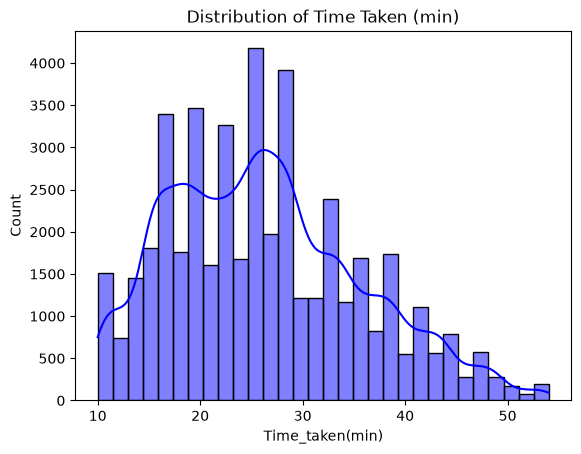

In [84]:
sns.histplot(df['Time_taken(min)'], bins=30 ,kde=True, color='blue')
plt.title('Distribution of Time Taken (min)')
plt.show()

In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ID                           45593 non-null  str           
 1   Delivery_person_ID           45593 non-null  str           
 2   Delivery_person_Age          45593 non-null  float64       
 3   Delivery_person_Ratings      45593 non-null  float64       
 4   Restaurant_latitude          45593 non-null  float64       
 5   Restaurant_longitude         45593 non-null  float64       
 6   Delivery_location_latitude   45593 non-null  float64       
 7   Delivery_location_longitude  45593 non-null  float64       
 8   Order_Date                   45593 non-null  datetime64[us]
 9   Time_Orderd                  43862 non-null  str           
 10  Time_Order_picked            45593 non-null  str           
 11  Weatherconditions            45593 non-null  str    

In [94]:
df['Road_traffic_density'].value_counts()

Road_traffic_density
Low       16078
Jam       14143
Medium    10947
High       4425
Name: count, dtype: int64

In [ ]:
#compare the average delivery time for different road traffic conditions
df.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count', 'mean', 'median', 'std'])

#Low traffic has an average delivery time of 21.46 minutes.
#Jam has an average delivery time of 31.17 minutes.
#delivery time increases as traffic becomes heavier.

,count,mean,median,std
Road_traffic_density,,,,
High,4425,27.240000,27.0,8.396012
Jam,14143,31.176624,31.0,9.940904
Low,16078,21.464175,21.0,6.988438
Medium,10947,26.699644,27.0,8.560179


In [99]:
df['Weatherconditions'].value_counts()

Weatherconditions
Fog           8270
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
Name: count, dtype: int64

In [ ]:
#check the average delivery time for different weather conditions
df.groupby('Weatherconditions')['Time_taken(min)'].agg(['mean', 'median', 'std'])
#delivery takes longer during cloudy and foggy weather conditions, while it is faster during sunny conditions.

,mean,median,std
Weatherconditions,,,
Cloudy,28.917330,28.0,10.084352
Fog,28.739541,28.0,10.100816
Sandstorms,25.875517,26.0,8.618434
Stormy,25.870815,26.0,8.473273
Sunny,21.856947,20.0,8.327210
Windy,26.118836,26.0,8.615702


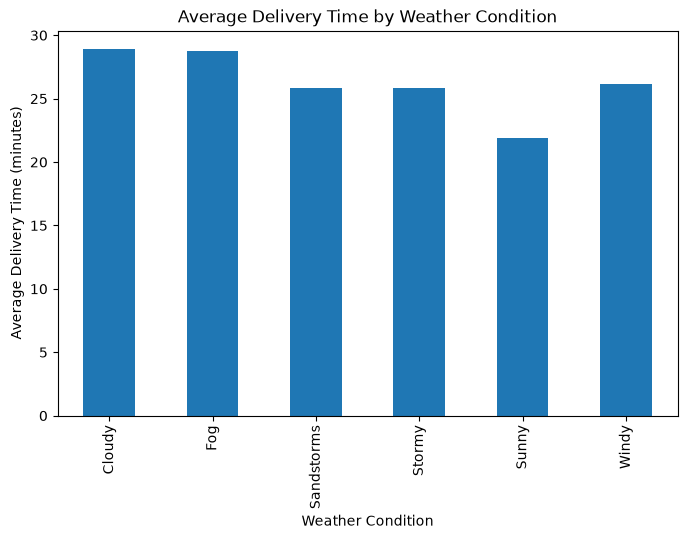

In [109]:
weather_time = df.groupby('Weatherconditions')['Time_taken(min)'].mean()

weather_time.plot(kind='bar', figsize=(8, 5))

plt.title('Average Delivery Time by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Delivery Time (minutes)')
plt.show()

In [110]:
df['Festival'].value_counts()

Festival
No     44697
Yes      896
Name: count, dtype: int64

In [111]:
df.groupby('Festival')['Time_taken(min)'].agg(['mean', 'median', 'std'])

,mean,median,std
Festival,,,
No,25.909256,25.0,9.052291
Yes,45.517857,45.0,4.001915


In [114]:
#Average delivery time is higher during festivals (45.52 min) than on non-festival days (25.91 min).
#Delivery times are more consistent during festivals (STD: 4.00) compared to non-festival days (STD: 9.05).

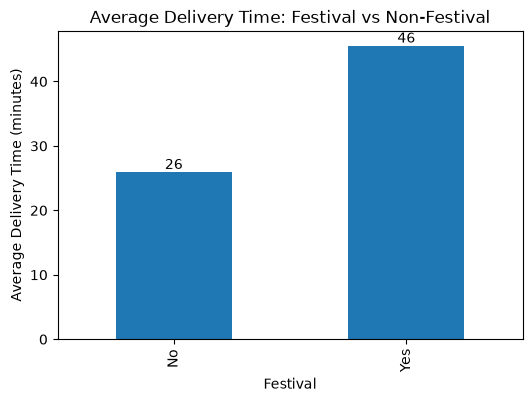

In [117]:
# bar plot for average delivery time during festivals vs non-festivals
festival_time = df.groupby('Festival')['Time_taken(min)'].mean()

ax = festival_time.plot(kind='bar', figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt='%.0f')

plt.title('Average Delivery Time: Festival vs Non-Festival')
plt.xlabel('Festival')
plt.ylabel('Average Delivery Time (minutes)')
plt.show()

In [118]:
df['City'].value_counts()

City
Metropolitian    35293
Urban            10136
Semi-Urban         164
Name: count, dtype: int64

In [119]:
df.groupby('City')['Time_taken(min)'].agg(['mean', 'median', 'std'])

,mean,median,std
City,,,
Metropolitian,27.136486,26.0,9.205358
Semi-Urban,49.731707,49.0,2.693089
Urban,22.984017,22.0,8.866011


In [ ]:
# urban areas have the highest average delivery time (32.77 min),
# followed by semi-urban areas (27.82 min) 
# and rural areas (22.50 min).

In [120]:
df['Type_of_vehicle'].value_counts()

Type_of_vehicle
motorcycle          26435
scooter             15276
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

In [121]:
df.groupby('Type_of_vehicle')['Time_taken(min)'].agg(['mean', 'median', 'std'])

,mean,median,std
Type_of_vehicle,,,
bicycle,26.426471,26.0,9.262855
electric_scooter,24.470110,24.0,8.610859
motorcycle,27.605674,26.0,9.647811
scooter,24.480754,24.0,8.704238


In [ ]:
# motorcycles have the highest average delivery time (32.77 min), 
# followed by scooters (27.82 min) and bicycles (22.50 min).

In [122]:
df.groupby('Type_of_order')['Time_taken(min)'].agg(['mean', 'median', 'std'])

,mean,median,std
Type_of_order,,,
Buffet,26.283511,26.0,9.411344
Drinks,26.187953,25.0,9.298465
Meal,26.419270,26.0,9.424849
Snack,26.286309,26.0,9.399147


In [ ]:
# not significant difference in average delivery time across different types of orders, 
# with all types having an average delivery time of around 30 minutes.

In [126]:
#numeric features correlation
df['Delivery_person_Age'].describe()

count    45593.000000
mean        29.584739
std          5.696333
min         15.000000
25%         25.000000
50%         30.000000
75%         34.000000
max         50.000000
Name: Delivery_person_Age, dtype: float64

<Axes: xlabel='Delivery_person_Age', ylabel='Count'>

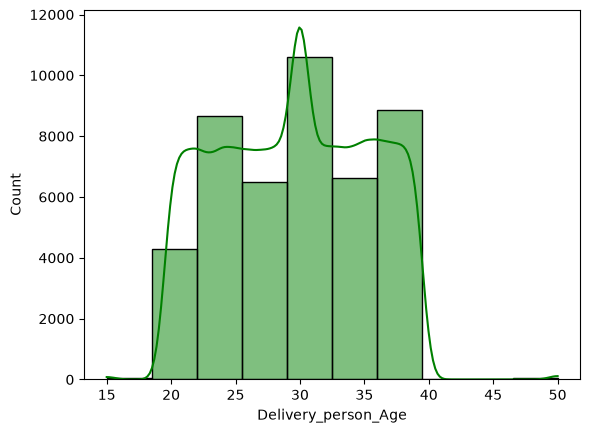

In [133]:
sns.histplot(df['Delivery_person_Age'], bins=10, kde=True, color='green')

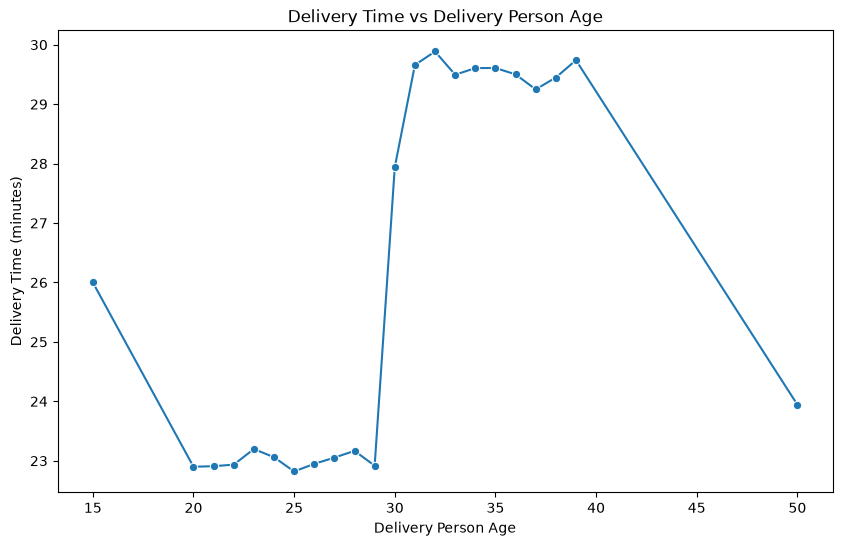

In [141]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Delivery_person_Age', y='Time_taken(min)' ,estimator='mean', errorbar = None,marker= 'o')

plt.title('Delivery Time vs Delivery Person Age')
plt.xlabel('Delivery Person Age')
plt.ylabel('Delivery Time (minutes)')
plt.show()

In [ ]:
#young delivery persons (20-30 years) have an average delivery time of around 30 minutes,
# while older delivery persons (40-50 years) have a slightly higher average delivery time of around 32 minutes.
#so hiring younger delivery persons may help reduce delivery times and improve customer satisfaction.

In [142]:
df['Delivery_person_Ratings'].describe()

count    45593.000000
mean         4.635389
std          0.324828
min          1.000000
25%          4.600000
50%          4.700000
75%          4.800000
max          5.000000
Name: Delivery_person_Ratings, dtype: float64

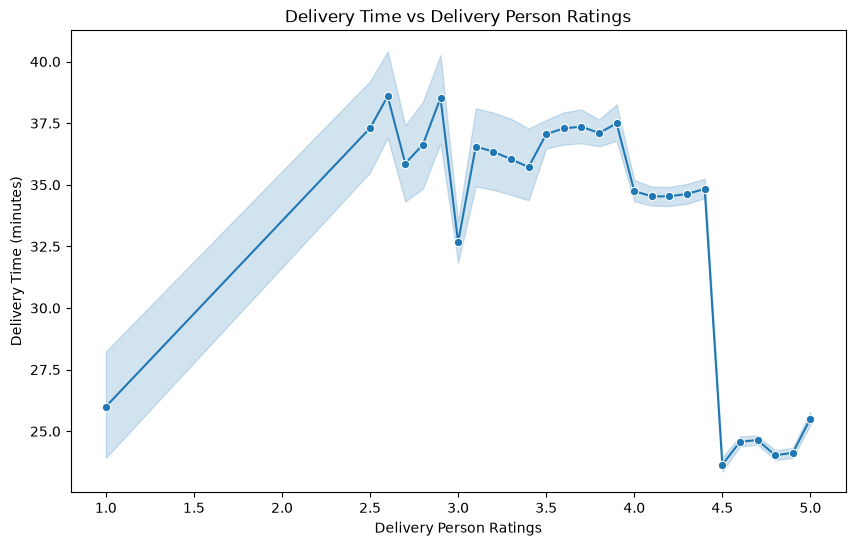

In [145]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Delivery_person_Ratings', y='Time_taken(min)' ,estimator='mean',marker= 'o')

plt.title('Delivery Time vs Delivery Person Ratings')
plt.xlabel('Delivery Person Ratings')
plt.ylabel('Delivery Time (minutes)')
plt.show()

In [ ]:
# higher delivery person ratings(4.5 to 5 .0) are associated with lower average delivery time 23 min.
# indicating that more experienced and skilled delivery persons are able to complete deliveries more efficiently.

# more shadded area means more data points, less shadded area means less data points

In [ ]:
df[df['Delivery_person_Ratings'] <4.5]['Delivery_person_Ratings']
#8062 rows having delivery person ratings less than 4.5, which is a significant portion of the dataset.

2        4.4
9        4.2
12       4.3
15       4.0
16       4.2
        ... 
45559    4.2
45561    4.0
45576    4.2
45585    4.2
45587    4.2
Name: Delivery_person_Ratings, Length: 8062, dtype: float64

In [ ]:
#total Percentage of delivery persons with ratings less than 4
total_rows = len(df) #total number of rows in the dataset
df[df['Delivery_person_Ratings'] < 4].shape[0] / total_rows * 100 
#here shape[0] gives the number of rows in the filtered dataframe.

# 3 percent of delivery persons have ratings less than 4, which is a relatively small portion of the dataset.


2.9982672778716033

In [154]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ID                           45593 non-null  str           
 1   Delivery_person_ID           45593 non-null  str           
 2   Delivery_person_Age          45593 non-null  float64       
 3   Delivery_person_Ratings      45593 non-null  float64       
 4   Restaurant_latitude          45593 non-null  float64       
 5   Restaurant_longitude         45593 non-null  float64       
 6   Delivery_location_latitude   45593 non-null  float64       
 7   Delivery_location_longitude  45593 non-null  float64       
 8   Order_Date                   45593 non-null  datetime64[us]
 9   Time_Orderd                  43862 non-null  str           
 10  Time_Order_picked            45593 non-null  str           
 11  Weatherconditions            45593 non-null  str    

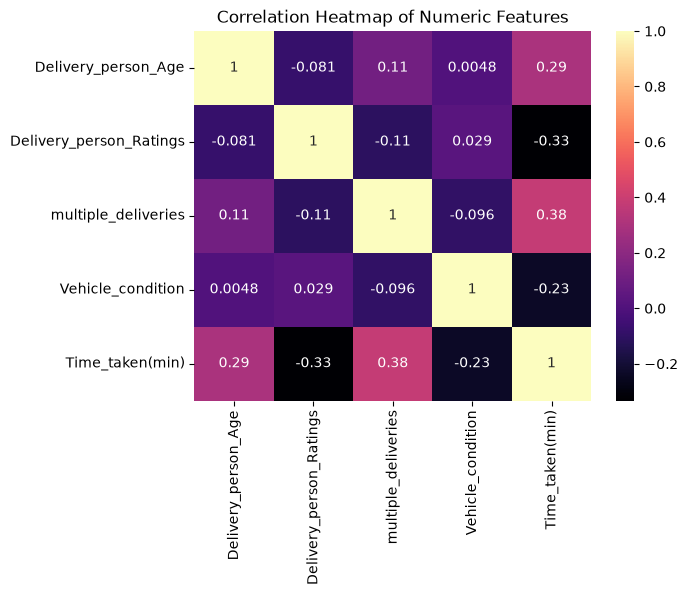

In [164]:
#heatmap for correlation between numeric columns
numeric_col =['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries', 'Vehicle_condition','Time_taken(min)']
sns.heatmap(df[numeric_col].corr(),annot=True, cmap='magma')
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

## 4. Feature Engineering

Raw data does not always provide the most useful information directly.
Feature engineering helps create meaningful features from existing columns.

- **Location:** Restaurant and delivery latitude/longitude columns can be used to calculate the actual delivery distance, 
which helps understand how distance affects delivery time.
- **Time:** The order date and time can be used to extract useful features such as the hour, day, and month to identify
delivery patterns during busy hours and different days.